In [7]:
# Cella 1: Import e Definizione Percorsi
import torch
import os
import glob
from PIL import Image
import numpy as np
from torch.utils.data import Dataset
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm  # Usiamo tqdm.notebook per Jupyter
from sklearn.model_selection import train_test_split

# --- IMPOSTAZIONE DEL DEVICE (GPU o CPU) ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device in uso: {device}")

# --- PERCORSI DEL DATASET ---
# Modifica questo flag se necessario
COLAB = False
if COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATASET_PATH = "/content/drive/MyDrive/Uni/Magistrale/colab/1/ML/Project/training/train"
else:
    # Assicurati che questo percorso sia corretto rispetto alla posizione del tuo notebook
    DATASET_PATH = "../../dataset/training/train" 
    
print(f"Percorso del dataset: {DATASET_PATH}")

NUM_WORKERS_TRAIN = 0  # Imposta a 0 su Windows se hai problemi
NUM_WORKERS_VAL = 0    # Imposta a 0 su Windows se hai problemi

Device in uso: cpu
Percorso del dataset: ../../dataset/training/train


Trovati 931 campioni validi dopo il filtraggio.
Inizio analisi del dataset (potrebbe richiedere qualche minuto)...


Analisi campioni:   0%|          | 0/931 [00:00<?, ?it/s]


--- Analisi Completata ---
Conteggio totale dei pixel per classe:
[ 14837133  78010390  69291002  78813041    954359   4489219  32365180
 187016896  52841916]

Frequenza dei pixel per classe (%):
[ 2.86089193 15.04194207 13.36067206 15.19670902  0.18401924  0.86560998
  6.24064516 36.06054675 10.18896379]


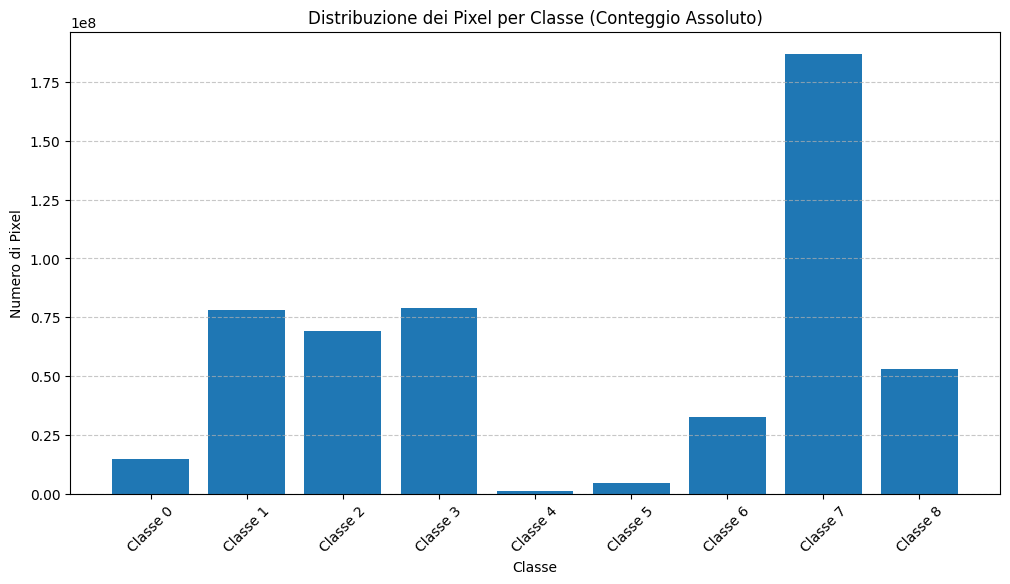


Forma dei metadati per la stratificazione: (931, 9)
Numero di campioni validi finali: 931
Esempio di metadato per il primo campione: [1 1 1 0 0 0 0 1 0]


In [8]:
# Cella 2: Analisi del Dataset e Creazione Metadati per lo Split (Versione Aggiornata)

def analyze_dataset(dataset_path):
    """
    Analizza il dataset per calcolare:
    1. La lista di tutti i percorsi validi dei campioni.
    2. Il conteggio totale dei pixel per ogni classe (da 0 a 8).
    3. I metadati per la stratificazione (un vettore binario per ogni immagine).
    """
    all_dirs = sorted(os.listdir(dataset_path))
    sample_dirs = []
    
    # Filtriamo le directory per assicurarci che siano campioni validi
    # e scartiamo cartelle come '__MACOSX' o file nascosti.
    for d in all_dirs:
        # Il campione deve essere una directory e il suo nome numerico (es. '0000')
        full_path = os.path.join(dataset_path, d)
        if os.path.isdir(full_path) and d.isdigit():
            sample_dirs.append(full_path)

    num_samples = len(sample_dirs)
    print(f"Trovati {num_samples} campioni validi dopo il filtraggio.")

    if num_samples == 0:
        raise FileNotFoundError(f"Nessun campione valido trovato nel percorso: {dataset_path}")

    # Assumiamo 9 classi (0-8)
    num_classes = 9
    pixel_counts = np.zeros(num_classes, dtype=np.int64)
    stratify_metadata = []
    
    # Lista per tenere traccia dei campioni che superano l'analisi
    # In caso di errori, possiamo usare questa lista "pulita" per lo split
    valid_sample_dirs = []

    print("Inizio analisi del dataset (potrebbe richiedere qualche minuto)...")
    for sample_dir in tqdm(sample_dirs, desc="Analisi campioni"):
        mask_path = os.path.join(sample_dir, 'labels.png')
        
        if not os.path.exists(mask_path):
            print(f"Attenzione: maschera non trovata in {sample_dir}. Campione saltato.")
            continue
        
        try:
            mask = Image.open(mask_path)
            mask_np = np.array(mask, dtype=np.uint8)
            
            # 1. Aggiorna conteggio pixel
            # np.bincount è molto efficiente per questo compito
            counts = np.bincount(mask_np.flatten(), minlength=num_classes)
            pixel_counts += counts
            
            # 2. Crea metadati per la stratificazione
            classes_present = np.unique(mask_np)
            stratify_vector = np.zeros(num_classes, dtype=np.int8)
            stratify_vector[classes_present] = 1
            stratify_metadata.append(stratify_vector)
            
            # Se tutto è andato a buon fine, aggiungiamo il campione alla lista dei validi
            valid_sample_dirs.append(sample_dir)
            
        except Exception as e:
            print(f"Errore nell'elaborazione del campione {sample_dir}: {e}. Campione saltato.")
            continue
            
    return valid_sample_dirs, pixel_counts, np.array(stratify_metadata)

# Eseguiamo l'analisi
all_sample_dirs, total_pixel_counts, stratify_data = analyze_dataset(DATASET_PATH)

# --- Verifica dell'analisi ---
print("\n--- Analisi Completata ---")
print(f"Conteggio totale dei pixel per classe:\n{total_pixel_counts}")

# Calcoliamo la frequenza per avere un'idea migliore dello sbilanciamento
total_pixels = total_pixel_counts.sum()
pixel_frequencies = total_pixel_counts / total_pixels
print(f"\nFrequenza dei pixel per classe (%):\n{pixel_frequencies * 100}")

# Visualizziamo la distribuzione
plt.figure(figsize=(12, 6))
plt.bar([f"Classe {i}" for i in range(len(total_pixel_counts))], total_pixel_counts)
plt.title("Distribuzione dei Pixel per Classe (Conteggio Assoluto)")
plt.ylabel("Numero di Pixel")
plt.xlabel("Classe")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print(f"\nForma dei metadati per la stratificazione: {stratify_data.shape}")
print(f"Numero di campioni validi finali: {len(all_sample_dirs)}")
print(f"Esempio di metadato per il primo campione: {stratify_data[0]}")

In [9]:
# Cella 3: Split Stratificato dei Dati (Versione Robusta)

# Definiamo i parametri dello split
VAL_SIZE = 0.2
RANDOM_STATE = 42 # Per la riproducibilità

# --- NUOVA STRATEGIA DI STRATIFICAZIONE ---
# Identifichiamo le classi rare. Basandoci sul grafico, diciamo che le classi con 
# meno del 5% di presenza in termini di immagini sono "rare".
# Eseguire la Cella 4 (anche solo mentalmente) ci aiuta a capire quali sono.
# Guardando i tuoi grafici iniziali, le classi 4 e 5 sono le più rare.
# Aggiungiamo anche la 6 e la 8 che sono meno frequenti.
CLASSI_RARE_INDICI = [4, 5, 6, 8] 

# Creiamo una nuova etichetta per lo split.
# L'etichetta sarà 1 se l'immagine contiene ALMENO UNA delle classi rare, 0 altrimenti.
# Questo crea solo due gruppi per la stratificazione, risolvendo il problema.
stratify_labels_semplificati = []
for vector in stratify_data:
    contiene_classe_rara = any(vector[i] == 1 for i in CLASSI_RARE_INDICI)
    stratify_labels_semplificati.append(1 if contiene_classe_rara else 0)

print("Stratificazione basata sulla presenza di classi rare.")
print(f"Numero di immagini con classi rare: {sum(stratify_labels_semplificati)}")
print(f"Numero di immagini senza classi rare: {len(stratify_labels_semplificati) - sum(stratify_labels_semplificati)}")


# Eseguiamo lo split usando le nuove etichette semplificate
try:
    train_dirs, val_dirs = train_test_split(
        all_sample_dirs,
        test_size=VAL_SIZE,
        random_state=RANDOM_STATE,
        stratify=stratify_labels_semplificati
    )
    
    print("\nSplit effettuato con successo!")
    print(f"- Campioni di training: {len(train_dirs)}")
    print(f"- Campioni di validazione: {len(val_dirs)}")

    print("\nEsempio di percorsi:")
    print(f"Training dir [0]: {train_dirs[0]}")
    print(f"Validation dir [0]: {val_dirs[0]}")

except ValueError as e:
    print(f"\nERRORE: Anche con la stratificazione semplificata, lo split non è possibile.")
    print(f"Dettagli: {e}")
    print("Questo potrebbe accadere se il numero totale di immagini con classi rare è molto basso.")
    print("Proviamo a eseguire uno split non stratificato come fallback.")
    train_dirs, val_dirs = train_test_split(
        all_sample_dirs,
        test_size=VAL_SIZE,
        random_state=RANDOM_STATE,
        shuffle=True # Shuffle è importante se non si stratifica
    )
    print("\nSplit non stratificato eseguito come fallback.")

Stratificazione basata sulla presenza di classi rare.
Numero di immagini con classi rare: 893
Numero di immagini senza classi rare: 38

Split effettuato con successo!
- Campioni di training: 744
- Campioni di validazione: 187

Esempio di percorsi:
Training dir [0]: ../../dataset/training/train\0412
Validation dir [0]: ../../dataset/training/train\0206


In [10]:
# %%
# Cella 4: Definizione delle Pipeline di Augmentation e Configurazione Globale

import albumentations as A
from albumentations.pytorch import ToTensorV2

def get_train_transforms(output_size):
    """
    Restituisce la pipeline di augmentation per il training set.
    Ora riceve output_size direttamente.
    """
    return A.Compose([
        A.Resize(height=output_size[0], width=output_size[1]), # Assicuriamoci che tutte le immagini abbiano la stessa dimensione
        A.HorizontalFlip(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=15, p=0.5),
        A.RandomBrightnessContrast(p=0.3),
        ToTensorV2(),
    ])

def get_val_transforms(output_size):
    """
    Restituisce solo ridimensionamento e conversione a tensore per il validation set.
    """
    return A.Compose([
        A.Resize(height=output_size[0], width=output_size[1]),
        ToTensorV2(),
    ])

print("Pipeline di Augmentation definite.")

Pipeline di Augmentation definite.


In [11]:
# %%
# Cella 5: Classe Dataset (Semplificata)
from typing import List, Tuple

class SegmentationDataset(Dataset):
    def __init__(self, sample_dirs: List[str], transform=None): # Non serve più output_size qui
        self.sample_dirs = sample_dirs
        self.transform = transform

    def __len__(self) -> int:
        return len(self.sample_dirs)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        sample_dir = self.sample_dirs[idx]
        img_path = os.path.join(sample_dir, 'rgb.jpg')
        mask_path = os.path.join(sample_dir, 'labels.png')

        image = np.array(Image.open(img_path).convert("RGB"))
        mask = np.array(Image.open(mask_path))

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']
        
        # Albumentations con ToTensorV2 restituisce già tensori,
        # ma ci assicuriamo che i tipi siano corretti.
        return image.float(), mask.long()

print("Classe SegmentationDataset definita.")

Classe SegmentationDataset definita.


In [12]:
# %%
# Cella 6: Istanziazione dei Dataset e DataLoader (CORRETTA)
from torch.utils.data import DataLoader

# 1. Creiamo le pipeline di trasformazioni usando il nostro config

train_transforms = get_train_transforms(config["OUTPUT_SIZE"]) 
val_transforms = get_val_transforms(config["OUTPUT_SIZE"])

# 2. Creiamo le istanze del DATASET, passando le directory e le trasformazioni
train_dataset = SegmentationDataset(sample_dirs=train_dirs, transform=train_transforms)
val_dataset = SegmentationDataset(sample_dirs=val_dirs, transform=val_transforms)

# 3. Creiamo i DataLoader usando i DATASET appena creati
train_loader = DataLoader(
    train_dataset, 
    batch_size=config["BATCH_SIZE"], 
    shuffle=True, 
    num_workers=NUM_WORKERS_TRAIN, 
    pin_memory=True
)
val_loader = DataLoader(
    val_dataset, 
    batch_size=config["BATCH_SIZE"], 
    shuffle=False, 
    num_workers=NUM_WORKERS_VAL, 
    pin_memory=True
)

print("\n--- Dataset e DataLoader creati correttamente ---")
print(f"Numero di batch nel training loader: {len(train_loader)}")
print(f"Numero di batch nel validation loader: {len(val_loader)}")

# Testiamo il caricamento di un batch
try:
    images, masks = next(iter(train_loader))
    print("\nVerifica di un batch:")
    print(f"Forma del tensore delle immagini: {images.shape}")
    print(f"Forma del tensore delle maschere: {masks.shape}")
    print(f"Tipo di dato immagini: {images.dtype}")
    print(f"Tipo di dato maschere: {masks.dtype}")
except Exception as e:
    print(f"\nErrore nel caricamento di un batch: {e}")


--- Dataset e DataLoader creati correttamente ---
Numero di batch nel training loader: 186
Numero di batch nel validation loader: 47

Verifica di un batch:
Forma del tensore delle immagini: torch.Size([4, 3, 544, 1024])
Forma del tensore delle maschere: torch.Size([4, 544, 1024])
Tipo di dato immagini: torch.float32
Tipo di dato maschere: torch.int64


c:\Users\Altair\AppData\Local\Programs\Python\Python313\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


# Loss Pesata

In [13]:
# Cella 6: Definizione del Modello, Loss Pesata e Ottimizzatore

# --- 1. CALCOLO DEI PESI PER LA LOSS ---
print("Calcolo dei pesi per la Cross Entropy Loss...")

# Usiamo i conteggi dei pixel calcolati in precedenza (total_pixel_counts)
# La formula è: peso = 1 / frequenza. 
# Per evitare pesi enormi, spesso si usa una variante smussata o logaritmica.
# Iniziamo con la versione standard: Inverse Frequency.

total_pixels = total_pixel_counts.sum()
class_frequencies = total_pixel_counts / total_pixels

# Calcoliamo i pesi: peso_c = 1 / freq_c
# Aggiungiamo un piccolo epsilon per evitare la divisione per zero se una classe non avesse pixel
weights = 1.0 / (class_frequencies + 1e-6)

# Normalizziamo i pesi in modo che il peso medio sia 1, per stabilità
weights = weights / weights.mean()

# Convertiamo i pesi in un tensore PyTorch e li spostiamo sul device corretto
class_weights_tensor = torch.tensor(weights, dtype=torch.float).to(device)

print("Pesi calcolati per ogni classe (normalizzati):")
for i, w in enumerate(class_weights_tensor):
    print(f"Classe {i}: {w.item():.2f}")


# --- 2. DEFINIZIONE DELLA FUNZIONE DI LOSS ---
# Usiamo CrossEntropyLoss, passandole i pesi e dicendole di ignorare la classe 0 (background/unlabeled) se necessario
# Il tuo dataset ha labels da 0 a 8. Se la classe 0 non è significativa, è bene ignorarla.
# Da quello che vedo la classe 0 è presente nel 100% delle immagini, quindi potrebbe essere 'background' o 'unlabeled'.
# Se è una classe valida (es. 'sky'), NON usare ignore_index.
# Assumiamo per ora di NON ignorarla.

criterion = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)
print(f"\nLoss function: CrossEntropyLoss con pesi personalizzati.")


Calcolo dei pesi per la Cross Entropy Loss...
Pesi calcolati per ogni classe (normalizzati):
Classe 0: 0.42
Classe 1: 0.08
Classe 2: 0.09
Classe 3: 0.08
Classe 4: 6.58
Classe 5: 1.40
Classe 6: 0.19
Classe 7: 0.03
Classe 8: 0.12

Loss function: CrossEntropyLoss con pesi personalizzati.


## Train With dummy model

In [14]:
# Cella 7 - Configurazione Esperimento

import segmentation_models_pytorch as smp

# --- Configurazione (mettila qui per chiarezza) ---
config = {
    "ENCODER": "resnet34", # Esempio, usa quello che preferisci
    "ENCODER_WEIGHTS": "imagenet",
    "NUM_CLASSES": 9
}

# --- 1. ISTANZIAZIONE DEL MODELLO ---
model = smp.Unet(
    encoder_name=config["ENCODER"],
    encoder_weights=config["ENCODER_WEIGHTS"],
    in_channels=3,
    classes=config["NUM_CLASSES"],
).to(device)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Modello smp.Unet con encoder {config['ENCODER']} istanziato. Parametri: {num_params:,}")


# --- 2. DEFINIZIONE DELLA LOSS (PESATA) ---
# Questo codice lo hai già, lo ricopiamo per completezza
total_pixels = total_pixel_counts.sum()
class_frequencies = total_pixel_counts / total_pixels
weights = 1.0 / (class_frequencies + 1e-6)
weights = weights / weights.mean()
class_weights_tensor = torch.tensor(weights, dtype=torch.float).to(device)

print("\nUtilizzo della LOSS PESATA.")
criterion = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)


# --- 3. DEFINIZIONE DELL'OTTIMIZZATORE ---
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

Modello smp.Unet con encoder resnet34 istanziato. Parametri: 24,437,529

Utilizzo della LOSS PESATA.


In [15]:

# Funzione per calcolare la mIoU (Intersection over Union)
def calculate_iou(preds, labels, num_classes):
    iou_scores = []
    # Convertiamo le predizioni in etichette di classe (argmax)
    preds = torch.argmax(preds, dim=1)
    
    for cls in range(num_classes):
        pred_inds = (preds == cls)
        target_inds = (labels == cls)
        
        intersection = (pred_inds[target_inds]).long().sum().item()
        union = pred_inds.long().sum().item() + target_inds.long().sum().item() - intersection
        
        if union == 0:
            # Se la classe non è presente né nella predizione né nel ground truth,
            # la IoU è 1 (perfetta per questa classe). Se è in uno ma non nell'altro,
            # l'intersezione è 0 e l'unione > 0, quindi la IoU sarà 0.
            iou_scores.append(1.0 if intersection == 0 else 0.0)
        else:
            iou_scores.append(intersection / union)
            
    return np.array(iou_scores)


def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    
    for images, masks in tqdm(loader, desc="Training"):
        images = images.to(device)
        masks = masks.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, masks)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        
    epoch_loss = running_loss / len(loader.dataset)
    return epoch_loss

def evaluate(model, loader, criterion, device, num_classes):
    model.eval()
    running_loss = 0.0
    total_iou = np.zeros(num_classes)
    
    with torch.no_grad():
        for images, masks in tqdm(loader, desc="Validation"):
            images = images.to(device)
            masks = masks.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, masks)
            
            running_loss += loss.item() * images.size(0)
            total_iou += calculate_iou(outputs, masks, num_classes)
            
    epoch_loss = running_loss / len(loader.dataset)
    mean_iou = total_iou / len(loader) # Media per batch
    
    return epoch_loss, mean_iou

In [16]:
# Cella 8: Ciclo di Training Principale

NUM_EPOCHS = 5 # Inizia con un numero basso per testare
best_val_miou = -1.0
NUM_CLASSES = 9
print("--- Inizio Training ---")

for epoch in range(NUM_EPOCHS):
    print(f"\n--- Epoch {epoch+1}/{NUM_EPOCHS} ---")
    
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    print(f"Training Loss: {train_loss:.4f}")
    
    val_loss, val_iou_per_class = evaluate(model, val_loader, criterion, device, NUM_CLASSES)
    val_miou = val_iou_per_class.mean() # Calcoliamo la mIoU media
    
    print(f"Validation Loss: {val_loss:.4f} | Validation mIoU: {val_miou:.4f}")
    
    # Stampa la IoU per ogni classe per un'analisi dettagliata
    print("IoU per classe:")
    for i, iou in enumerate(val_iou_per_class):
        print(f"  Classe {i}: {iou:.4f}")
        
    # Salva il modello migliore
    if val_miou > best_val_miou:
        best_val_miou = val_miou
        print(f"*** Nuovo modello migliore trovato! mIoU: {val_miou:.4f}. Lo salvo... ***")
        torch.save(model.state_dict(), 'best_model.pth')

print("\n--- Training Completato ---")

--- Inizio Training ---

--- Epoch 1/5 ---


Training:   0%|          | 0/186 [00:00<?, ?it/s]

KeyboardInterrupt: 